# Домашняя работа 1 "Интерполяционный полином Лагранжа"
**Колпакова Дарья Сергеевна, группа J3112, ИСУ 501390**

**Вариант 11**

Функция: $$ f(x) = \frac{1}{3} + \cos(10 + 2.3^{|x|}) $$

Интервал: $$ x \in [-1; 2.5] $$


In [7]:
import numpy as np
import matplotlib.pyplot as plt

# Настройка размера графиков
plt.rcParams['figure.figsize'] = [12, 6]

# 1. Определение функции
def f(x):
    return 1/3 + np.cos(10 + 2.3**np.abs(x))

In [8]:
# 2. Реализация интерполяционного полинома Лагранжа
def Lagrange_interpolation(x_nodes, y_nodes, t):
    """
    x_nodes: массив координат узлов
    y_nodes: массив значений функции в узлах
    t: точка (или массив точек), в которой вычисляется полином
    """
    n = len(x_nodes)
    if np.ndim(t) > 0:
        result = np.zeros_like(t, dtype=float)
        for idx, t_val in enumerate(t):
            val = 0.0
            for i in range(n):
                L_i = 1.0
                for j in range(n):
                    if i != j:
                        L_i *= (t_val - x_nodes[j]) / (x_nodes[i] - x_nodes[j])
                val += y_nodes[i] * L_i
            result[idx] = val
        return result
    else:
        result = 0.0
        for i in range(n):
            L_i = 1.0
            for j in range(n):
                if i != j:
                    L_i *= (t - x_nodes[j]) / (x_nodes[i] - x_nodes[j])
            result += y_nodes[i] * L_i
        return result

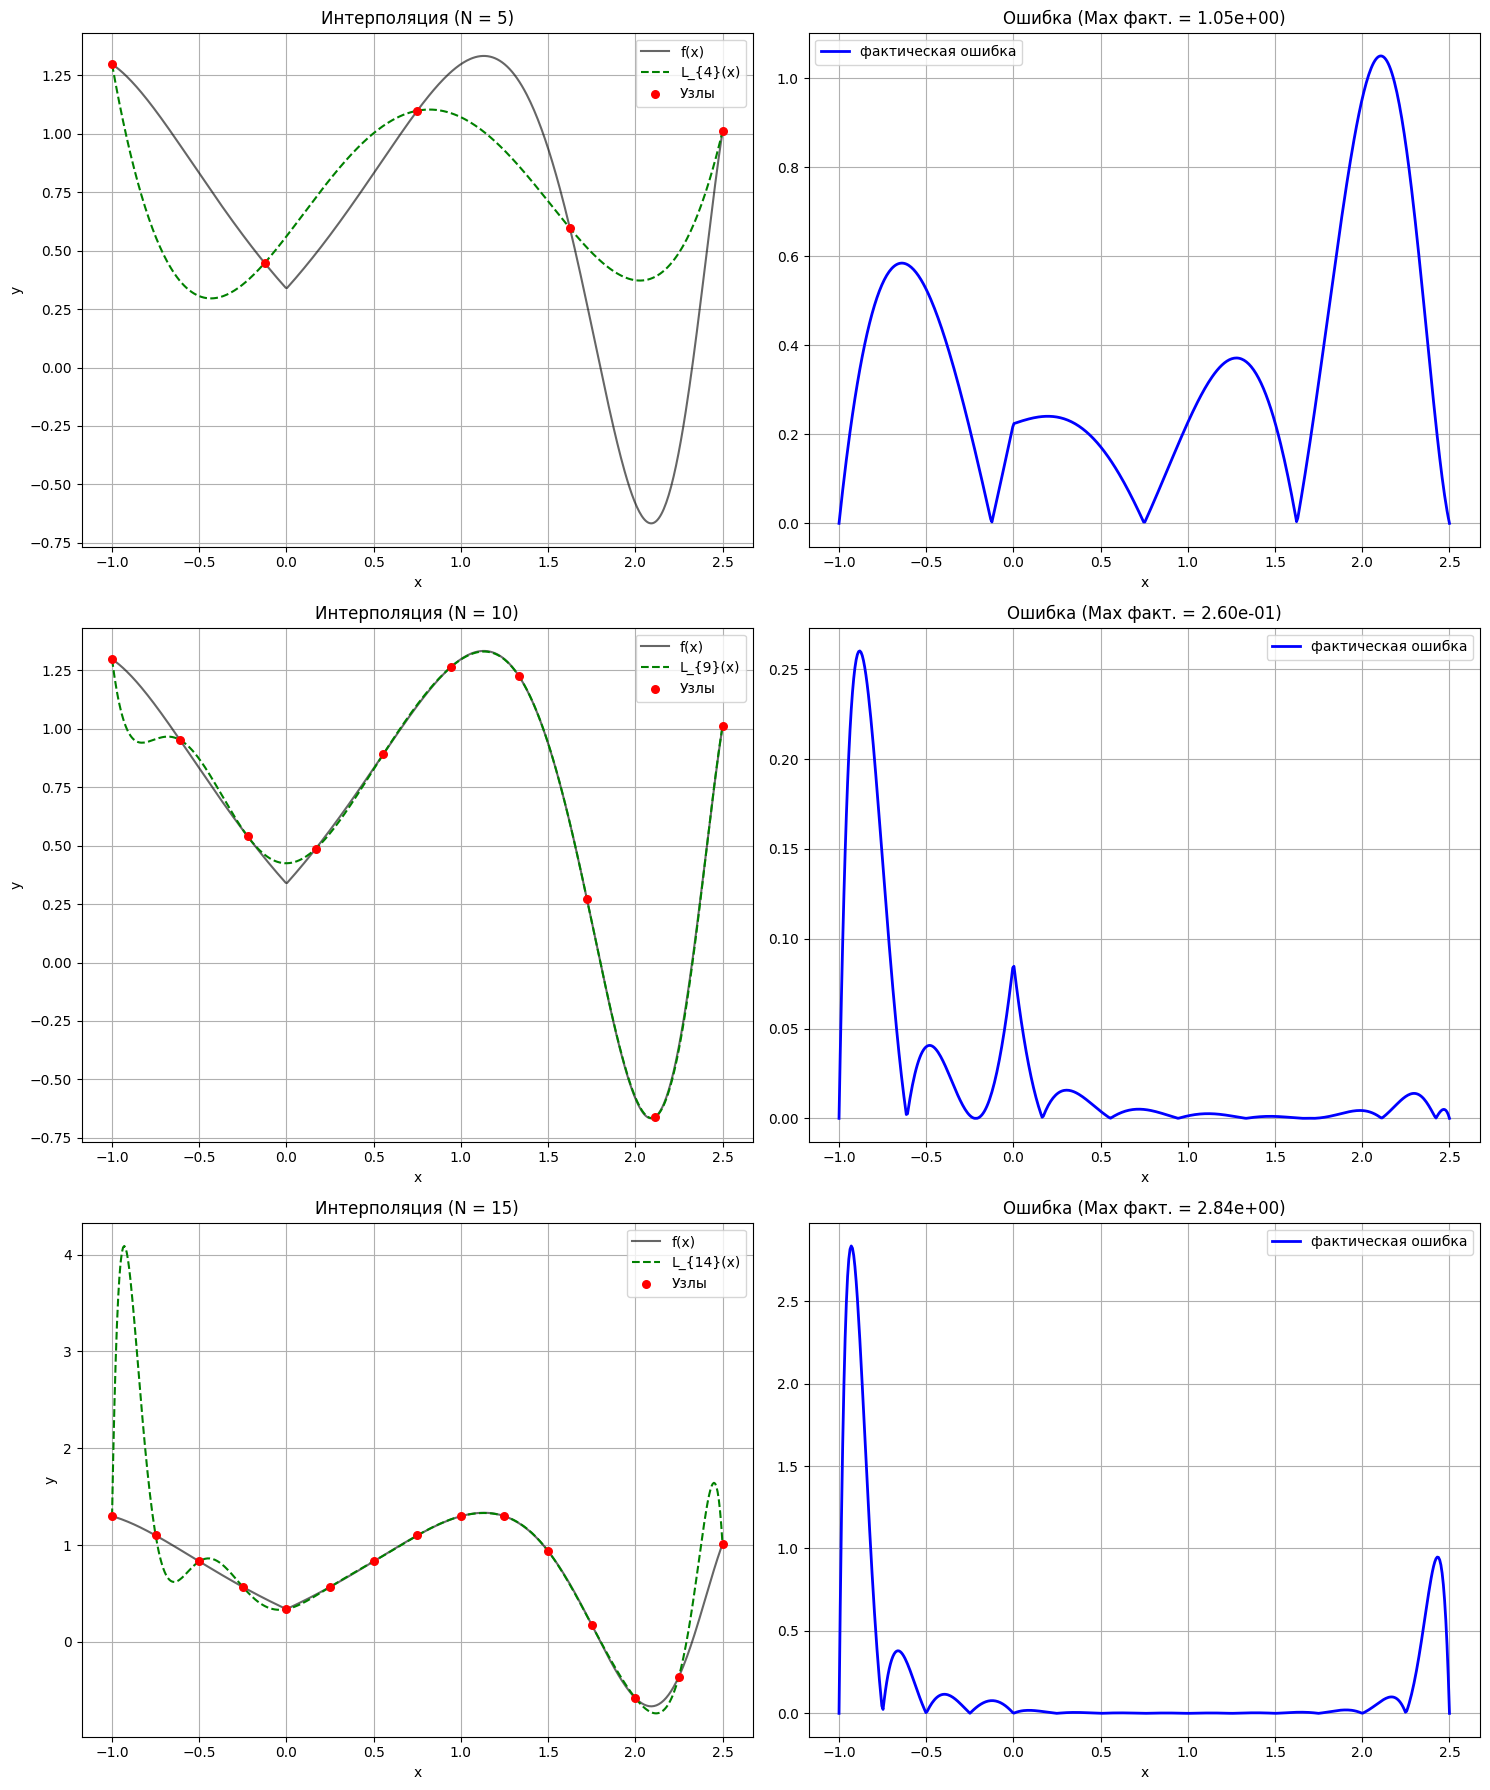


РАСЧЕТНЫЕ ДАННЫЕ
Количество узлов N = 5: Максимальная ошибка приближения = 1.049798e+00
Количество узлов N = 10: Максимальная ошибка приближения = 2.602931e-01
Количество узлов N = 15: Максимальная ошибка приближения = 2.835049e+00


In [9]:
# 3. Вычисления и построение графиков

a, b = -1, 2.5
node_counts = [5, 10, 15]


x_dense = np.linspace(a, b, 500)
y_dense = f(x_dense)

# Словарь для хранения результатов расчетов
results = {}

plt.figure(figsize=(15, 6 * len(node_counts)))

for i, n_nodes in enumerate(node_counts):
    x_nodes = np.linspace(a, b, n_nodes)
    y_nodes = f(x_nodes)

    y_poly = Lagrange_interpolation(x_nodes, y_nodes, x_dense)

    actual_error = np.abs(y_dense - y_poly)
    max_err = np.max(actual_error)

    results[n_nodes] = max_err

    # График 1: Функция и Полином
    plt.subplot(len(node_counts), 2, 2*i + 1)
    plt.plot(x_dense, y_dense, 'k-', label='f(x)', alpha=0.6)
    plt.plot(x_dense, y_poly, 'g--', label=f'L_{{{n_nodes-1}}}(x)')
    plt.scatter(x_nodes, y_nodes, color='red', s=30, label='Узлы', zorder=5)
    plt.title(f'Интерполяция (N = {n_nodes})')
    plt.xlabel('x')
    plt.ylabel('y')
    plt.legend()
    plt.grid(True)

    # График 2: Фактическая ошибка
    plt.subplot(len(node_counts), 2, 2*i + 2)
    plt.plot(x_dense, actual_error, 'b-', label='фактическая ошибка', linewidth=2)
    plt.title(f'Ошибка (Max факт. = {max_err:.2e})')
    plt.xlabel('x')
    plt.legend()
    plt.grid(True)

plt.tight_layout()
plt.show()

# Вывод основных расчетных данных
print("\nРАСЧЕТНЫЕ ДАННЫЕ")
for n, err in results.items():
    print(f"Количество узлов N = {n}: Максимальная ошибка приближения = {err:.6e}")

### Оценка ошибки сверху

Оценим ошибку приближения сверху. Ошибку определим как норму на отрезке $[a;b]$:

$$ \varepsilon = \|R_m(x)\|_{C[a;b]} = \sup_{x \in [a;b]} |R_m(x)| = \max_{x \in [a;b]} |R_m(x)| $$

тогда:

$$ \varepsilon \le \frac{\|f^{(m+1)}(\eta)\|_{C[a;b]}}{(m+1)!} \|\omega(x)\|_{C[a;b]} $$

Также можно записать еще одну оценку ошибки:

$$ \varepsilon(x) \le \frac{M_{m+1}}{(m+1)!} |\omega(x)| $$

где:

$$ M_{m+1} \ge \max_{x \in [a;b]} |f^{(m+1)}(x)| $$

**Анализ применимости:**

Для корректного использования этой формулы функция $f(x)$ должна быть $(m+1)$ раз непрерывно дифференцируема на заданном отрезке.

Рассмотрим функцию:
$$ f(x) = \frac{1}{3} + \cos(10 + 2.3^{|x|}) $$

Из-за наличия модуля $|x|$, первая производная функции в точке $x=0$ (которая входит в интервал $[-1, 2.5]$) терпит разрыв первого рода:
- При $x \to 0^+$ производная стремится к значению $A > 0$.
- При $x \to 0^-$ производная стремится к значению $-A < 0$.

Так как производная не существует в точке $x=0$, функция не принадлежит классу $C^1[-1, 2.5]$ (и тем более $C^{m+1}$).

**Вывод:** Сделать строгую классическую оценку ошибки сверху через производные нельзя.